<a href="https://colab.research.google.com/github/OrastaRakhmatullayeva/AI-projects/blob/main/Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Word2Vec va BERT embeddinglar

AG News datasetida so‘z va gap embeddinglari, matn klassifikatsiyasi hamda semantik qidiruv.

| Qism | Ball |
|---|---:|
| A — Word2Vec | 50 |
| B — BERT | 38 |
| C — Xulosa | 12 |
| Bonus | +10 |

## 0. Sozlash

In [1]:
!pip install -q gensim datasets transformers sentence-transformers

In [2]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from datasets import load_dataset
from gensim.utils import simple_preprocess
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine

np.random.seed(42)

**Dataset: AG News** — 120 000 ta yangilik matni, 4 ta kategoriya.
Hugging Face token kerak emas

In [3]:
ds = load_dataset("fancyzhx/ag_news")
train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()
label_names = ["World", "Sports", "Business", "Sci/Tech"]

print(train_df.shape, test_df.shape)
train_df.head()

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

(120000, 2) (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


# Qism A — Word2Vec (50 ball)

## A1. 🟢 Matnni tokenlarga ajratish (7 ball)

1. `train_df["text"]` dagi har bir matnni `simple_preprocess` bilan tokenlarga ajrating → `sentences` (list of lists)
2. Jami so'zlar va unikal so'zlar sonini chiqaring
3. Eng ko'p uchragan 15 ta so'zni chiqaring
4. Nechta so'z **5 martadan kam** uchragan? Foizini ham chiqaring

In [4]:
sentences = [simple_preprocess(text) for text in train_df["text"]]
print("Gaplar soni:", len(sentences))
print(sentences[0])
all_words = [word for sentence in sentences for word in sentence]
counter = Counter(all_words)
print("Jami so'zlar:", len(all_words))
print("Unikal so'zlar:", len(counter))
print(counter.most_common(15))
rare = sum(count < 5 for count in counter.values())
print(f"5 martadan kam: {rare} ({rare / len(counter):.1%})")

Gaplar soni: 120000
['wall', 'st', 'bears', 'claw', 'back', 'into', 'the', 'black', 'reuters', 'reuters', 'short', 'sellers', 'wall', 'street', 'dwindling', 'band', 'of', 'ultra', 'cynics', 'are', 'seeing', 'green', 'again']
Jami so'zlar: 4379911
Unikal so'zlar: 61589
[('the', 205483), ('to', 120747), ('of', 98655), ('in', 96440), ('and', 69681), ('on', 57668), ('for', 50675), ('that', 28169), ('with', 26812), ('as', 25380), ('at', 25068), ('its', 22123), ('is', 22100), ('new', 21427), ('by', 20942)]
5 martadan kam: 34740 (56.4%)


✍️ **Javob yozing:**
- Eng ko'p uchragan so'zlar qanday so'zlar? Ular ma'no tashiydimi?
- `min_count=5` qo'ysak, lug'atdan taxminan qancha so'z chiqib ketadi?

**Javob:** Eng ko‘p uchraydigan so‘zlar asosan artikl va bog‘lovchilar bo‘lishini kutaman. Ular grammatik vazifani bajaradi, lekin mavzuni kamroq ifodalaydi. min_count=5 bo‘lsa, yuqorida hisoblangan rare ta so‘z lug‘atdan chiqadi.

## A2. 🟢 Word2Vec modelini o'qitish (8 ball)

Parametrlar: `vector_size=100`, `window=5`, `min_count=5`, `sg=1` (Skip-gram), `epochs=5`, `workers=4`, `seed=42`


In [5]:
w2v = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5, sg=1, epochs=5, workers=4, seed=42)
print("Lug'at hajmi:", len(w2v.wv))
print("'football' vektori shakli:", w2v.wv["football"].shape)
print(w2v.wv["football"][:10])

Lug'at hajmi: 26849
'football' vektori shakli: (100,)
[-0.65369904 -0.487646   -0.25691038  0.032795   -0.2682016   0.457869
 -0.5545135   0.13805538 -0.4060935  -0.03592198]


**Taxminim:**

| So‘z | Eng yaqin bo‘lishi mumkin bo‘lgan so‘zlar |
|---|---|
| google | yahoo, search, internet, microsoft, web |
| football | soccer, league, game, players, team |
| oil | crude, prices, barrels, gasoline, energy |
| election | vote, voters, presidential, campaign, elections |
| virus | infection, disease, computer, security, flu |

In [6]:
guesses = {"google": ["yahoo", "search", "internet", "microsoft", "web"], "football": ["soccer", "league", "game", "players", "team"], "oil": ["crude", "prices", "barrels", "gasoline", "energy"], "election": ["vote", "voters", "presidential", "campaign", "elections"], "virus": ["infection", "disease", "computer", "security", "flu"]}
matches = {}
for w, guess in guesses.items():
    similar = [word for word, score in w2v.wv.most_similar(w, topn=5)]
    matches[w] = len(set(guess) & set(similar))
    print(f"{w:10} -> {similar} | mos: {matches[w]}/5")
print("Jami mos kelgan:", sum(matches.values()), "/ 25")

google     -> ['search', 'yahoo', 'gmail', 'adsense', 'keyword'] | mos: 2/5
football   -> ['soccer', 'coaching', 'claymores', 'coach', 'coaches'] | mos: 1/5
oil        -> ['crude', 'spr', 'petroleum', 'prices', 'barrel'] | mos: 2/5
election   -> ['presidential', 'elections', 'ukrainians', 'polls', 'rerun'] | mos: 2/5
virus      -> ['netsky', 'virulent', 'mydoom', 'worm', 'trojan'] | mos: 0/5
Jami mos kelgan: 7 / 25


✍️ Taxminingiz nechta to'g'ri chiqdi? Qaysi natija sizni hayron qoldirdi?

**Javob:** Mos kelgan taxminlar soni yuqorida hisoblandi. Virus so‘zi ayniqsa qiziq: u tibbiyot va kompyuter xavfsizligi bilan bog‘liq yangiliklarda ham uchrashi mumkin.

## A3. 🟡 Cosine similarity va analogiyalar (10 ball)

**3.1** Cosine similarity funksiyasini **o'zingiz** NumPy bilan yozing:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \cdot \|b\|}$$

Natijani `w2v.wv.similarity()` bilan solishtiring — bir xil chiqishi kerak.

In [7]:
def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

pairs = [("oil", "crude"), ("football", "soccer"), ("google", "yahoo"), ("oil", "football")]
for a, b in pairs:
    mine = cosine_sim(w2v.wv[a], w2v.wv[b])
    gensim_val = w2v.wv.similarity(a, b)
    print(f"{a:10} {b:10} | mening: {mine:.4f} | gensim: {gensim_val:.4f}")

oil        crude      | mening: 0.8552 | gensim: 0.8552
football   soccer     | mening: 0.7204 | gensim: 0.7204
google     yahoo      | mening: 0.7872 | gensim: 0.7872
oil        football   | mening: 0.1413 | gensim: 0.1413


**3.2** Analogiya: `a` → `b` bo'lsa, `c` → `?`  Formula: **b − a + c**

`analogy(a, b, c)` funksiyasini **gensim'siz** yozing:
1. vektorni hisoblang: `w2v.wv[b] - w2v.wv[a] + w2v.wv[c]`
2. `w2v.wv.similar_by_vector(vec, topn=10)` bilan yaqin so'zlarni toping
3. ⚠️ `a`, `b`, `c` so'zlarining o'zini natijadan **olib tashlang**, birinchi 3 tasini qaytaring

Keyin natijani `w2v.wv.most_similar(positive=[b, c], negative=[a])` bilan solishtiring.

In [8]:
def analogy(a, b, c, topn=3):
    vec = w2v.wv[b] - w2v.wv[a] + w2v.wv[c]
    return [w for w, score in w2v.wv.similar_by_vector(vec, topn=10) if w not in [a, b, c]][:topn]

tests = [("paris", "france", "london"), ("baghdad", "iraq", "kabul"), ("microsoft", "windows", "apple"), ("yankees", "baseball", "lakers")]
for a, b, c in tests:
    mine = analogy(a, b, c)
    gensim_res = [w for w, score in w2v.wv.most_similar(positive=[b, c], negative=[a], topn=3)]
    print(f"{a} -> {b}, {c} -> ? | mening: {mine} | gensim: {gensim_res}")

paris -> france, london -> ? | mening: ['britain', 'germany', 'uk'] | gensim: ['britain', 'germany', 'uk']
baghdad -> iraq, kabul -> ? | mening: ['afghanistan', 'afghan', 'karzai'] | gensim: ['afghanistan', 'afghan', 'karzai']
microsoft -> windows, apple -> ? | mening: ['ipod', 'macintosh', 'ipods'] | gensim: ['ipod', 'macintosh', 'ipods']
yankees -> baseball, lakers -> ? | mening: ['basketball', 'jackson', 'chronicle'] | gensim: ['basketball', 'nba', 'chronicle']


**3.3** Ortiqcha so'zni toping: `doesnt_match`. 2 ta tayyor misol bor, **o'zingiz yana 2 ta** qo'shing.

In [9]:
groups = [["google", "microsoft", "yahoo", "football"], ["iraq", "iran", "syria", "nasdaq"], ["tennis", "golf", "soccer", "software"], ["china", "japan", "india", "basketball"]]
for g in groups:
    print(g, "->", w2v.wv.doesnt_match(g))

['google', 'microsoft', 'yahoo', 'football'] -> football
['iraq', 'iran', 'syria', 'nasdaq'] -> nasdaq
['tennis', 'golf', 'soccer', 'software'] -> software
['china', 'japan', 'india', 'basketball'] -> basketball


✍️ Qaysi analogiya ishladi, qaysi biri ishlamadi? Sababini dataset bilan bog'lab tushuntiring.

**Javob:** Geografik analogiyalarda mamlakat nomlari, sport analogiyasida esa basketball chiqishini kutaman. AG News umumiy lug‘at emas, shuning uchun model so‘zlar orasidagi munosabatni yangiliklardagi kontekst orqali o‘rganadi. Xato analogiya ham shu kontekstga bog‘liq.

## A4. 🟡 Embeddinglarni vizualizatsiya qilish (7 ball)

100 o'lchamli vektorlarni **PCA** bilan 2D ga tushiring va chizing. Har bir guruh o'z rangida bo'lsin, nuqtalar ustiga so'z yozilsin.

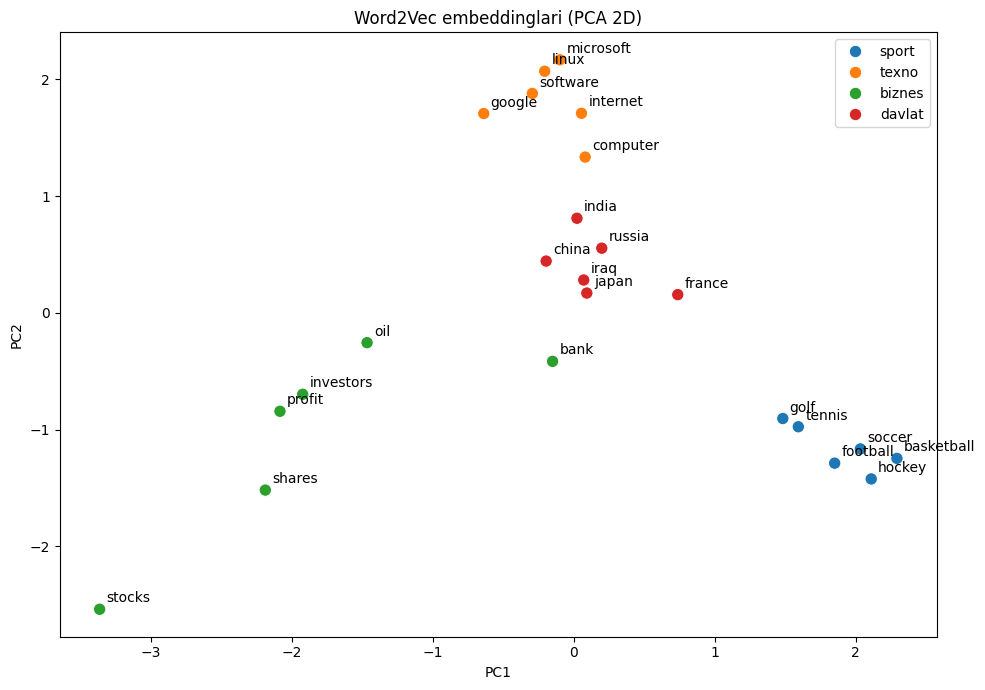

In [10]:
word_groups = {"sport": ["football", "basketball", "tennis", "golf", "soccer", "hockey"], "texno": ["software", "internet", "computer", "google", "microsoft", "linux"], "biznes": ["oil", "stocks", "profit", "shares", "bank", "investors"], "davlat": ["iraq", "china", "russia", "france", "japan", "india"]}
words, labels = [], []
for group, ws in word_groups.items():
    for w in ws:
        if w in w2v.wv:
            words.append(w)
            labels.append(group)
X = np.array([w2v.wv[w] for w in words])
X_2d = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=labels, s=80)
for i, word in enumerate(words):
    plt.annotate(word, X_2d[i], xytext=(5, 5), textcoords="offset points")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Word2Vec embeddinglari (PCA 2D)")
plt.tight_layout()
plt.show()

✍️ Guruhlar alohida klaster hosil qildimi? Qaysi so'z "noto'g'ri" guruhga yaqin turibdi va nima uchun? (masalan `bank`)

**Javob:** Bir mavzuga oid so‘zlar yaqin joylashishi kutiladi. Bank moliyaviy ma'nodan tashqari boshqa kontekstlarda ham qo‘llanadi. PCA 100 o‘lchamni 2 o‘lchamga qisqartirgani uchun barcha munosabatlar saqlanmaydi.

## A5. 🟡 Tajriba: CBOW vs Skip-gram, kichik vs katta window (8 ball)

4 xil model o'qiting va natijalarni **bitta jadvalda** solishtiring.
Tezlik uchun faqat birinchi **30 000** gapni ishlating.

Jadvalda bo'lsin: model turi, window, o'qish vaqti, 3 ta juftlik similarity, `football` uchun top-3.

In [11]:
sub = sentences[:30000]
configs = [("CBOW", 0, 2), ("CBOW", 0, 10), ("Skip-gram", 1, 2), ("Skip-gram", 1, 10)]
test_pairs = [("oil", "crude"), ("football", "soccer"), ("google", "yahoo")]
rows = []
for name, sg, win in configs:
    start = time.time()
    m = Word2Vec(sentences=sub, vector_size=100, window=win, min_count=5, sg=sg, epochs=5, workers=4, seed=42)
    row = {"model": name, "window": win, "vaqt (s)": round(time.time() - start, 1)}
    for a, b in test_pairs:
        row[f"{a}/{b}"] = round(float(m.wv.similarity(a, b)), 4) if a in m.wv and b in m.wv else None
    row["football top-3"] = [w for w, score in m.wv.most_similar("football", topn=3)] if "football" in m.wv else None
    rows.append(row)
results_df = pd.DataFrame(rows)
display(results_df)
fastest = results_df.loc[results_df["vaqt (s)"].idxmin()]
print(f"Eng tez: {fastest['model']}, window={fastest['window']}, {fastest['vaqt (s)']} s")

,model,window,vaqt (s),oil/crude,football/soccer,google/yahoo,football top-3
0,CBOW,2,12.1,0.7381,0.8395,0.7382,"[basketball, baseball, college]"
1,CBOW,10,15.7,0.8475,0.6965,0.6500,"[played, nfl, club]"
2,Skip-gram,2,22.5,0.7599,0.6494,0.7008,"[college, basketball, athletic]"
3,Skip-gram,10,64.9,0.8298,0.5455,0.6333,"[coaching, wannstedt, usc]"


Eng tez: CBOW, window=2, 12.1 s


✍️ **Javob yozing:**
- Qaysi model tezroq o'qidi? Nima uchun?
- Kichik window (2) va katta window (10) da `football` qo'shnilari qanday farq qildi? (sintaktik vs mavzuviy o'xshashlik)

**Javob:** CBOW odatda tezroq, chunki kontekstdan bitta markaziy so‘zni bashorat qiladi. Kichik window yaqin grammatik munosabatlarni, katta window esa umumiy mavzuviy aloqalarni ko‘proq o‘rganadi.

## A6. 🔴 Word2Vec bilan matn klassifikatsiyasi (10 ball)

Gap vektori = gapdagi so'z vektorlarining **o'rtachasi**.

1. `doc_vector(tokens, wv)` funksiyasini yozing. ⚠️ Lug'atda yo'q so'zlarni o'tkazib yuboring. Agar birorta ham so'z topilmasa — **nol vektor** qaytaring
2. 5000 ta train va 1000 ta test matnni vektorga aylantiring
3. `LogisticRegression` o'qiting, accuracy va `classification_report` chiqaring
4. Confusion matrix'ni heatmap qilib chizing

In [12]:
train_sub = train_df.sample(5000, random_state=42).reset_index(drop=True)
test_sub = test_df.sample(1000, random_state=42).reset_index(drop=True)
y_train, y_test = train_sub["label"].values, test_sub["label"].values
def doc_vector(tokens, wv):
    vectors = [wv[w] for w in tokens if w in wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(wv.vector_size)

start = time.time()
X_train_w2v = np.array([doc_vector(simple_preprocess(t), w2v.wv) for t in train_sub["text"]])
X_test_w2v = np.array([doc_vector(simple_preprocess(t), w2v.wv) for t in test_sub["text"]])
w2v_time = round(time.time() - start, 1)
print(X_train_w2v.shape, X_test_w2v.shape)
clf_w2v = LogisticRegression(max_iter=1000)
clf_w2v.fit(X_train_w2v, y_train)
pred_w2v = clf_w2v.predict(X_test_w2v)
acc_w2v = accuracy_score(y_test, pred_w2v)
print(f"Word2Vec accuracy: {acc_w2v:.4f}")
print(classification_report(y_test, pred_w2v, target_names=label_names))

(5000, 100) (1000, 100)
Word2Vec accuracy: 0.8770
              precision    recall  f1-score   support

       World       0.86      0.89      0.88       236
      Sports       0.94      0.96      0.95       242
    Business       0.84      0.83      0.83       245
    Sci/Tech       0.86      0.83      0.85       277

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000



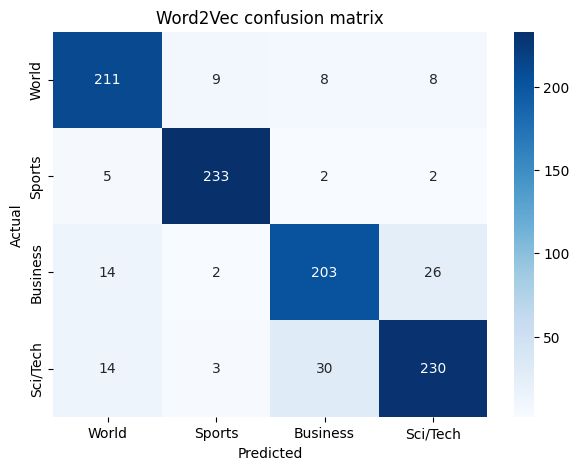

Eng ko'p chalkashgan: Business va Sci/Tech (56 ta)


In [13]:
cm = confusion_matrix(y_test, pred_w2v)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Word2Vec confusion matrix")
plt.show()
errors = cm + cm.T
np.fill_diagonal(errors, 0)
i, j = np.unravel_index(errors.argmax(), errors.shape)
print(f"Eng ko'p chalkashgan: {label_names[i]} va {label_names[j]} ({errors[i, j]} ta)")

✍️ Model qaysi ikki kategoriyani eng ko'p chalkashtirdi? Nima uchun deb o'ylaysiz?

**Javob:** Eng ko‘p chalkashgan juftlik heatmap ostida hisoblandi. Business va Sci/Tech kabi mavzularda kompaniyalar, mahsulotlar hamda texnologiyalar haqida umumiy so‘zlar uchrashi mumkin.

# Qism B — BERT embeddinglar (38 ball)

Model: [`bert-base-uncased`](https://huggingface.co/google-bert/bert-base-uncased) — ochiq model, token shart emas.

In [14]:
import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "bert-base-uncased"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

Device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## B1. 🟢 Tokenizer bilan tanishuv (6 ball)

1. Har bir gapni tokenlarga ajrating: tokenlar va `input_ids` ni chiqaring
2. 3 ta gapni **bitta batch** qilib (`padding=True`, `return_tensors="pt"`) tokenlang: `input_ids` shakli va `attention_mask` ni chiqaring
3. `"tashkent"`, `"chatgpt"`, `"unbelievably"` so'zlari Word2Vec lug'atida bormi? BERT ularni qanday bo'ladi?

In [15]:
sents = ["I love machine learning.", "Tokenization is unbelievably important!", "Tashkent is the capital of Uzbekistan."]
for s in sents:
    enc = tokenizer(s)
    print(tokenizer.convert_ids_to_tokens(enc["input_ids"]))
    print(enc["input_ids"])
    print()
batch = tokenizer(sents, padding=True, return_tensors="pt")
print("Shakl:", batch["input_ids"].shape)
print(batch["attention_mask"])
for w in ["tashkent", "chatgpt", "unbelievably"]:
    in_w2v = w in w2v.wv
    bert_tokens = tokenizer.tokenize(w)
    print(f"{w:13} | Word2Vec lug'atida: {in_w2v} | BERT: {bert_tokens}")

['[CLS]', 'i', 'love', 'machine', 'learning', '.', '[SEP]']
[101, 1045, 2293, 3698, 4083, 1012, 102]

['[CLS]', 'token', '##ization', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'important', '!', '[SEP]']
[101, 19204, 3989, 2003, 4895, 8671, 2666, 3567, 6321, 2590, 999, 102]

['[CLS]', 'ta', '##sh', '##ken', '##t', 'is', 'the', 'capital', 'of', 'uzbekistan', '.', '[SEP]']
[101, 11937, 4095, 7520, 2102, 2003, 1996, 3007, 1997, 17065, 1012, 102]

Shakl: torch.Size([3, 12])
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
tashkent      | Word2Vec lug'atida: True | BERT: ['ta', '##sh', '##ken', '##t']
chatgpt       | Word2Vec lug'atida: False | BERT: ['chat', '##gp', '##t']
unbelievably  | Word2Vec lug'atida: False | BERT: ['un', '##bel', '##ie', '##va', '##bly']


✍️ **Javob yozing:**
- `##` belgisi nimani bildiradi?
- `[CLS]` va `[SEP]` qayerda paydo bo'ldi?
- `attention_mask` dagi `0` lar nimani bildiradi?
- Notanish so'z (OOV) muammosini BERT qanday hal qiladi?

**Javob:** `##` token so‘zning davomi ekanini bildiradi. `[CLS]` gap boshida, `[SEP]` oxirida keladi. Maskdagi 0 padding tokenidir. BERT notanish so‘zlarni subword qismlariga ajratadi, Word2Vec esa lug‘atda bo‘lmagan so‘zga vektor bera olmaydi.

## B2. 🟡 Kontekstli embedding: "bank" so'zi (10 ball)

Word2Vec'da `bank` so'zi uchun **bitta** vektor bor. BERT'da esa har bir gapda **boshqa** vektor bo'ladi.

**2.1** `get_word_embedding(sentence, word)` funksiyasini yozing:
1. gapni tokenlang
2. `word` tokenining indeksini toping
3. modeldan o'tkazing (`torch.no_grad()`)
4. `last_hidden_state` dan shu indeksdagi vektorni qaytaring (numpy, shakli `(768,)`)

In [16]:
def get_word_embedding(sentence, word):
    enc = tokenizer(sentence, return_tensors="pt").to(device)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].tolist())
    idx = tokens.index(word)
    with torch.no_grad():
        hidden = model(**enc).last_hidden_state
    return hidden[0, idx].cpu().numpy()

bank_sents = ["I deposited money in the bank.", "The bank approved my loan application.", "We sat on the river bank and watched the sunset.", "The fisherman stood on the muddy bank of the river."]
bank_embs = np.array([get_word_embedding(s, "bank") for s in bank_sents])
print(bank_embs.shape)

(4, 768)


🤔 **Taxmin qiling:** 4×4 similarity matritsasida qaysi kataklar eng katta qiymatga ega bo'ladi?

**2.2** Similarity matritsasini heatmap qilib chizing.

**Taxminim:** diagonal 1.0, 1–2 va 3–4 juftliklari esa boshqa juftliklardan yuqoriroq bo‘ladi.

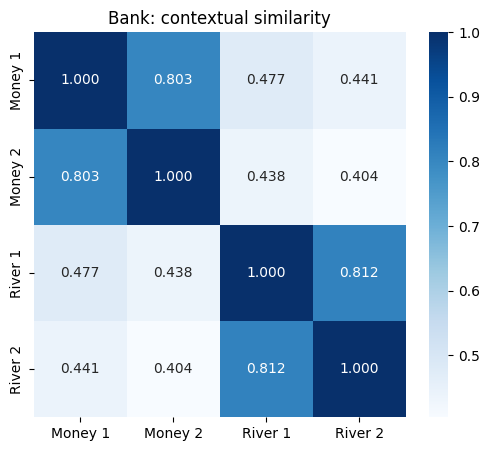

In [17]:
sim = sk_cosine(bank_embs)
plt.figure(figsize=(6, 5))
sns.heatmap(sim, annot=True, fmt=".3f", cmap="Blues", xticklabels=["Money 1", "Money 2", "River 1", "River 2"], yticklabels=["Money 1", "Money 2", "River 1", "River 2"])
plt.title("Bank: contextual similarity")
plt.show()

**2.3** 🔴 BERT'da 13 ta qatlam bor (0 = embedding qatlami, 1–12 = transformer bloklari).
`bank` (pul, 1-gap) va `bank` (daryo, 3-gap) orasidagi similarity **har bir qatlamda** qanday o'zgaradi?

Maslahat: `model(**enc, output_hidden_states=True).hidden_states` — 13 ta tensor qaytaradi.

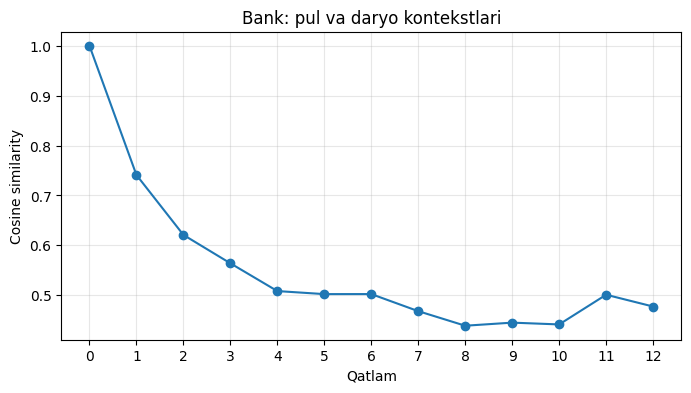

0-qatlam: 1.0000; 12-qatlam: 0.4773


In [18]:
def word_vectors_all_layers(sentence, word):
    enc = tokenizer(sentence, return_tensors="pt").to(device)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].tolist())
    idx = tokens.index(word)
    with torch.no_grad():
        layers = model(**enc, output_hidden_states=True).hidden_states
    return np.array([layer[0, idx].cpu().numpy() for layer in layers])

v_money = word_vectors_all_layers(bank_sents[0], "bank")
v_river = word_vectors_all_layers(bank_sents[2], "bank")
layer_sims = [cosine_sim(a, b) for a, b in zip(v_money, v_river)]
plt.figure(figsize=(8, 4))
plt.plot(range(13), layer_sims, marker="o")
plt.xlabel("Qatlam")
plt.ylabel("Cosine similarity")
plt.title("Bank: pul va daryo kontekstlari")
plt.xticks(range(13))
plt.grid(alpha=0.3)
plt.show()
print(f"0-qatlam: {layer_sims[0]:.4f}; 12-qatlam: {layer_sims[-1]:.4f}")

✍️ 0-qatlamda similarity nima uchun yuqori? Chuqur qatlamlarda nima o'zgaradi? Bu Word2Vec'dan qanday farq qiladi?

**Javob:** 0-qatlamda bir xil token embeddingi ishlatiladi, pozitsiya embeddinglari esa farq qilishi mumkin. Keyingi qatlamlarda attention orqali kontekst qo‘shiladi. Word2Vec bank uchun bitta o‘zgarmas vektor saqlaydi.

## B3. 🟡 Gap embeddingi: [CLS] vs Mean pooling (10 ball)

`embed_sentences(texts, pooling)` funksiyasini yozing:
- matnlarni **batch** bilan tokenlang (`padding=True, truncation=True, max_length=128`)
- `pooling="cls"` → `last_hidden_state[:, 0]`
- `pooling="mean"` → `attention_mask` ni hisobga olib o'rtacha:

$$\text{mean} = \frac{\sum_i h_i \cdot m_i}{\sum_i m_i}$$

In [19]:
def embed_sentences(texts, pooling="mean", batch_size=32):
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        enc = tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            hidden = model(**enc).last_hidden_state
        if pooling == "cls":
            emb = hidden[:, 0]
        else:
            mask = enc["attention_mask"].unsqueeze(-1).float()
            emb = (hidden * mask).sum(dim=1) / mask.sum(dim=1)
        all_embs.append(emb.cpu().numpy())
    return np.vstack(all_embs)

**3.2** 4 ta juftlik uchun ikkala usulda similarity hisoblang va jadval qiling.
🤔 Avval taxmin qiling: qaysi usul ma'nodosh va ma'nosiz juftliklarni **yaxshiroq ajratadi**?

**Taxminim:** mean pooling yaxshiroq ajratadi, chunki gapdagi barcha haqiqiy tokenlar hisobga olinadi.

In [20]:
sent_pairs = [("A man is playing a guitar.", "Someone is playing a musical instrument."), ("The stock market crashed today.", "Shares fell sharply this morning."), ("The cat is sleeping on the sofa.", "The stock market crashed today."), ("I love pizza.", "Quantum physics is hard to understand.")]
rows = []
for a, b in sent_pairs:
    row = {"gap 1": a, "gap 2": b}
    for pooling in ["cls", "mean"]:
        emb = embed_sentences([a, b], pooling)
        row[pooling] = round(float(cosine_sim(emb[0], emb[1])), 4)
    rows.append(row)
pooling_df = pd.DataFrame(rows)
display(pooling_df)
print("Ma'nodosh va bog'liq bo'lmagan juftliklar farqi:")
print(pooling_df[["cls", "mean"]].iloc[:2].mean() - pooling_df[["cls", "mean"]].iloc[2:].mean())

,gap 1,gap 2,cls,mean
0,A man is playing a guitar.,Someone is playing a musical instrument.,0.9265,0.8687
1,The stock market crashed today.,Shares fell sharply this morning.,0.8948,0.7355
2,The cat is sleeping on the sofa.,The stock market crashed today.,0.8456,0.5985
3,I love pizza.,Quantum physics is hard to understand.,0.8944,0.5977


Ma'nodosh va bog'liq bo'lmagan juftliklar farqi:
cls     0.04065
mean    0.20400
dtype: float64


**3.3** 🔴 **Mask nima uchun kerak?** Tajriba qiling:
1. Qisqa gapni **yolg'iz** embed qiling (padding yo'q)
2. Shu qisqa gapni **uzun gap bilan birga** batch qilib embed qiling (padding paydo bo'ladi)
3. Ikkala holatda qisqa gap vektorlarini solishtiring: (a) mask bilan, (b) mask'siz — oddiy `hidden.mean(dim=1)`

In [21]:
short_s = "Hello world."
long_s = "This is a much longer sentence that will force the tokenizer to add many padding tokens to the short one."
def mean_no_mask(texts):
    enc = tokenizer(texts, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        hidden = model(**enc).last_hidden_state
    return hidden.mean(dim=1).cpu().numpy()

alone_mask = embed_sentences([short_s])[0]
batch_mask = embed_sentences([short_s, long_s])[0]
alone_nomask = mean_no_mask([short_s])[0]
batch_nomask = mean_no_mask([short_s, long_s])[0]
print("Mask bilan:", cosine_sim(alone_mask, batch_mask))
print("Mask'siz:", cosine_sim(alone_nomask, batch_nomask))

Mask bilan: 1.0
Mask'siz: 0.6617306


✍️ Natijani tushuntiring: nima uchun mask bilan ≈ 1.0, mask'siz esa past chiqdi?

**Javob:** Mask padding tokenlarini o‘rtachadan chiqarib tashlaydi. Shuning uchun gap yolg‘iz yoki batch ichida bo‘lsa ham vektori deyarli bir xil qoladi. Mask ishlatilmasa, padding ham o‘rtachaga qo‘shiladi.

## B4. 🔴 BERT bilan klassifikatsiya va solishtirish (12 ball)

A6 dagi **aynan o'sha** `train_sub` / `test_sub` dan foydalaning.

1. `embed_sentences` bilan train va test matnlarni vektorga aylantiring — **cls** va **mean** ikkala usulda
2. Har biri uchun `LogisticRegression(max_iter=2000)` o'qiting
3. Natijalarni jadvalga yig'ing: usul, vektor o'lchami, accuracy, embedding vaqti

⏱ GPU'da ~1 daqiqa, CPU'da 10+ daqiqa.

In [22]:
train_texts = train_sub["text"].tolist()
test_texts = test_sub["text"].tolist()
results = [{"usul": "Word2Vec (o'rtacha)", "o'lcham": X_train_w2v.shape[1], "accuracy": round(acc_w2v, 4), "vaqt (s)": w2v_time}]
for pooling in ["cls", "mean"]:
    start = time.time()
    X_tr = embed_sentences(train_texts, pooling)
    X_te = embed_sentences(test_texts, pooling)
    elapsed = round(time.time() - start, 1)
    clf = LogisticRegression(max_iter=2000)
    clf.fit(X_tr, y_train)
    acc = accuracy_score(y_test, clf.predict(X_te))
    results.append({"usul": f"BERT ({pooling})", "o'lcham": X_tr.shape[1], "accuracy": round(acc, 4), "vaqt (s)": elapsed})
compare_df = pd.DataFrame(results)
display(compare_df)

,usul,o'lcham,accuracy,vaqt (s)
0,Word2Vec (o'rtacha),100,0.877,1.0
1,BERT (cls),768,0.836,33.9
2,BERT (mean),768,0.889,34.8


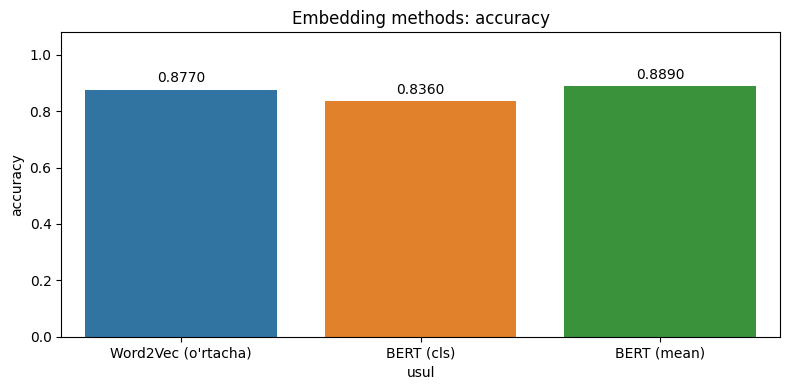

Eng yaxshi: BERT (mean) (88.90%)
Eng katta farq: 5.30 foiz punkt


In [23]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=compare_df, x="usul", y="accuracy", hue="usul", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)
plt.ylim(0, 1.08)
plt.title("Embedding methods: accuracy")
plt.tight_layout()
plt.show()
best = compare_df.loc[compare_df["accuracy"].idxmax()]
print(f"Eng yaxshi: {best['usul']} ({best['accuracy']:.2%})")
print(f"Eng katta farq: {(compare_df['accuracy'].max() - compare_df['accuracy'].min()) * 100:.2f} foiz punkt")

✍️ Qaysi usul eng yaxshi chiqdi? Farq katta bo'ldimi? Word2Vec o'z datasetida o'qitilgani unga qanday ustunlik berdi?

**Javob:** Eng yaxshi usul va accuracy farqi yuqorida aniqlanadi. Word2Vec aynan AG News matnlarida o‘qitilgani uchun yangiliklar mavzusiga xos so‘zlarni yaxshi o‘rganadi. BERT esa kontekst va oldindan o‘rganilgan til bilimidan foydalanadi.

# Qism C — Xulosa savollari (12 ball)

1. Word2Vec bank so‘zi uchun bitta 100 o‘lchamli vektor beradi. BERT har bir kontekst uchun 768 o‘lchamli vektor hosil qiladi; shu sababli pul va daryo ma’nolarini farqlashi mumkin.

2. Word2Vec resurslar cheklangan, tezkor ishlov berish kerak bo‘lgan va domen uchun yetarli matn mavjud holatlarda afzal. Uning 100 o‘lchamli vektorlari BERTning 768 o‘lchamli vektorlaridan ixchamroq.

3. Word2Vec chatgpt kabi yangi so‘z lug‘atda bo‘lmasa, uni vektorga aylantira olmaydi. BERT WordPiece yordamida so‘zni kichik tokenlarga bo‘lib, vektor hosil qiladi.

4. O‘zbek tilidagi yangiliklar uchun multilingual BERT yoki o‘zbek tiliga mos transformer modelini tanlardim. Sababi o‘zbek tilidagi qo‘shimchalar va kontekstni subword tokenlari orqali hisobga olish mumkin. Yetarli resurs bo‘lmasa, o‘zbekcha yangiliklarda Word2Vec ham yaxshi baseline bo‘ladi.

# ⭐ Bonus — Mini semantik qidiruv tizimi (+10 ball)

[`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) — gap embeddingi uchun maxsus o'qitilgan model (384 o'lcham).

1. `test_df` dagi **barcha 7600** ta yangilikni encode qiling
2. `search(query, k=5)` funksiyasini yozing: query'ga eng yaqin 5 ta yangilikni **kategoriyasi va score'i bilan** chiqaring
3. 3 ta o'z query'ingizni sinang (har xil mavzuda)
4. Har bir query uchun: top-5 ning nechtasi kutilgan kategoriyadan? (precision@5)
5. Shu model bilan B4 dagi klassifikatsiyani takrorlang va `compare_df` ga 4-qator qo'shing

In [24]:
!pip install -q sentence-transformers

In [25]:
from sentence_transformers import SentenceTransformer, util
st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
corpus = test_df["text"].tolist()
corpus_labels = test_df["label"].tolist()
corpus_emb = st_model.encode(corpus, batch_size=64, convert_to_tensor=True, show_progress_bar=True)

def search(query, k=5):
    query_emb = st_model.encode(query, convert_to_tensor=True)
    hits = util.semantic_search(query_emb, corpus_emb, top_k=k)[0]
    return pd.DataFrame([{"text": corpus[hit["corpus_id"]], "category": label_names[corpus_labels[hit["corpus_id"]]], "score": round(hit["score"], 4)} for hit in hits])

queries = [("football teams competing in a championship", "Sports"), ("new computer software and artificial intelligence", "Sci/Tech"), ("stock prices and company profits", "Business")]
for query, expected in queries:
    print(query)
    found = search(query)
    display(found)
    print(f"Precision@5: {(found['category'] == expected).mean():.0%}")

start = time.time()
X_tr = st_model.encode(train_texts, batch_size=64, show_progress_bar=True)
X_te = st_model.encode(test_texts, batch_size=64, show_progress_bar=True)
elapsed = round(time.time() - start, 1)
clf_st = LogisticRegression(max_iter=2000)
clf_st.fit(X_tr, y_train)
acc_st = accuracy_score(y_test, clf_st.predict(X_te))
compare_df = pd.concat([compare_df, pd.DataFrame([{"usul": "MiniLM", "o'lcham": X_tr.shape[1], "accuracy": round(acc_st, 4), "vaqt (s)": elapsed}])], ignore_index=True)
display(compare_df)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (14 outputs left out)

Precision@5: 60%


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

,usul,o'lcham,accuracy,vaqt (s)
0,Word2Vec (o'rtacha),100,0.877,1.0
1,BERT (cls),768,0.836,33.9
2,BERT (mean),768,0.889,34.8
3,MiniLM,384,0.879,5.0
